# Milestone 3 — P1.EDA & Statistics
**Dataset:** `AI4I_with_synthetic_data_cleaned_data.csv` (12,500 row)


**Notebook Map:** Step 0 Sanity Check → Step 1 Descriptive Statistics → Step 2 Probabilities & Imbalance → Step 3 The Six Plots → Step 4 Correlation

In [4]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['figure.dpi'] = 100
df = pd.read_csv('C:\\Users\\user\\Downloads\\milestone3\\AI4I_with_synthetic_data_cleaned_data.csv')

num_cols = ['Air temperature [K]', 'Process temperature [K]',
            'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
target = 'Machine failure'

## Step 0 — (Sanity Check)

In [5]:
print('Shape      :', df.shape)
print('Nulls      :', int(df.isna().sum().sum()))
print('Duplicates :', int(df.duplicated().sum()))
print()
df.info()
df.head()

Shape      : (12500, 14)
Nulls      : 0
Duplicates : 0

<class 'pandas.DataFrame'>
RangeIndex: 12500 entries, 0 to 12499
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      12500 non-null  int64  
 1   Product ID               12500 non-null  str    
 2   Type                     12500 non-null  str    
 3   Air temperature [K]      12500 non-null  float64
 4   Process temperature [K]  12500 non-null  float64
 5   Rotational speed [rpm]   12500 non-null  int64  
 6   Torque [Nm]              12500 non-null  float64
 7   Tool wear [min]          12500 non-null  int64  
 8   Machine failure          12500 non-null  int64  
 9   TWF                      12500 non-null  int64  
 10  HDF                      12500 non-null  int64  
 11  PWF                      12500 non-null  int64  
 12  OSF                      12500 non-null  int64  
 13  RNF                      12500 

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## Step 1 — (Descriptive Statistics)

In [6]:
stats_summary = pd.DataFrame({
    'Mean'    : df[num_cols].mean(),
    'Median'  : df[num_cols].median(),
    'Mode'    : [df[c].mode()[0] for c in num_cols],
    'Variance': df[num_cols].var(),
    'Std_Dev' : df[num_cols].std(),
    'Q1 (25%)': df[num_cols].quantile(0.25),
    'Q3 (75%)': df[num_cols].quantile(0.75),
    'P90'     : df[num_cols].quantile(0.90),
    'Skew'    : df[num_cols].skew(),
}).round(2)
stats_summary

,Mean,Median,Mode,Variance,Std_Dev,Q1 (25%),Q3 (75%),P90,Skew
Air temperature [K],300.18,300.2,300.70,4.40,2.10,298.4,301.9,303.0,0.03
Process temperature [K],310.10,310.2,310.60,2.56,1.60,308.8,311.3,312.2,-0.08
Rotational speed [rpm],1520.99,1496.0,1953.00,30918.35,175.84,1398.0,1620.0,1761.0,0.63
Torque [Nm],41.44,40.9,72.55,158.83,12.60,32.8,48.7,57.8,0.35
Tool wear [min],115.14,116.0,2.00,4547.27,67.43,57.0,176.0,203.0,-0.06


## Step 2 — (Probability & Class Imbalance)

In [7]:
# Where does the 12,500-row file come from?  First 10,000 = original AI4I rows, rest = synthetic.
orig = df[df['UDI'] <= 10000]
syn  = df[df['UDI'] >  10000]

imb = pd.DataFrame({
    'Rows'        : [len(orig), len(syn), len(df)],
    'Failures'    : [orig[target].sum(), syn[target].sum(), df[target].sum()],
    'Failure rate %': [orig[target].mean()*100, syn[target].mean()*100, df[target].mean()*100],
}, index=['Original (UDI<=10000)', 'Synthetic (UDI>10000)', 'Whole file']).round(2)
display(imb)

p_fail = df[target].mean()
print(f'P(Failure) overall = {p_fail*100:.2f}%')

,Rows,Failures,Failure rate %
Original (UDI<=10000),10000,339,3.39
Synthetic (UDI>10000),2500,2500,100.00
Whole file,12500,2839,22.71


P(Failure) overall = 22.71%


In [8]:
def cond_prob(mask, name):
    p_in  = df.loc[mask,  target].mean()
    p_out = df.loc[~mask, target].mean()
    print(f'{name:32s}  P(F|cond)={p_in*100:5.2f}%   P(F|not cond)={p_out*100:5.2f}%   Risk x{p_in/p_out:.2f}')

cond_prob(df['Torque [Nm]']    > 50,  'Torque > 50 Nm')
cond_prob(df['Tool wear [min]'] > 200, 'Tool wear > 200 min')
cond_prob(df['Rotational speed [rpm]'] < df['Rotational speed [rpm]'].quantile(0.25), 'Speed < Q1 (low rpm)')

Torque > 50 Nm                    P(F|cond)=51.16%   P(F|not cond)=14.79%   Risk x3.46
Tool wear > 200 min               P(F|cond)=56.55%   P(F|not cond)=18.16%   Risk x3.11
Speed < Q1 (low rpm)              P(F|cond)=49.53%   P(F|not cond)=13.84%   Risk x3.58


## Step 3 — (Matplotlib)

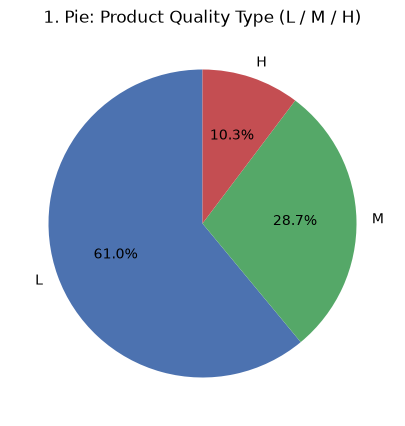

Takeaway: 61% of machines are Low-quality (L). Failure share overall = 22.71% vs OK = 77.29%.


In [9]:
# 1) PIE — Product quality types
type_counts = df['Type'].value_counts()
plt.figure(figsize=(5,5))
plt.pie(type_counts, labels=type_counts.index, autopct='%1.1f%%', startangle=90,
        colors=['#4C72B0', '#55A868', '#C44E52'])
plt.title('1. Pie: Product Quality Type (L / M / H)')
plt.show()

fr = df[target].value_counts(normalize=True)*100
print(f'Takeaway: 61% of machines are Low-quality (L). Failure share overall = {fr[1]:.2f}% vs OK = {fr[0]:.2f}%.')

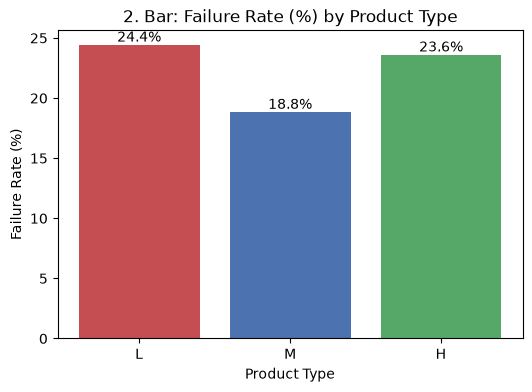

{'L': 24.4, 'M': 18.81, 'H': 23.58}
Takeaway: failure rates are fairly close across L/M/H -> product type alone is a WEAK predictor; it does not explain failures.


In [10]:
# 2) BAR — Failure rate by Type
fail_by_type = (df.groupby('Type')[target].mean()*100).reindex(['L','M','H'])
plt.figure(figsize=(6,4))
plt.bar(fail_by_type.index, fail_by_type.values, color=['#C44E52','#4C72B0','#55A868'])
plt.title('2. Bar: Failure Rate (%) by Product Type')
plt.xlabel('Product Type'); plt.ylabel('Failure Rate (%)')
for i, v in enumerate(fail_by_type.values): plt.text(i, v+0.3, f'{v:.1f}%', ha='center')
plt.show()
print(fail_by_type.round(2).to_dict())
print('Takeaway: failure rates are fairly close across L/M/H -> product type alone is a WEAK predictor; it does not explain failures.')

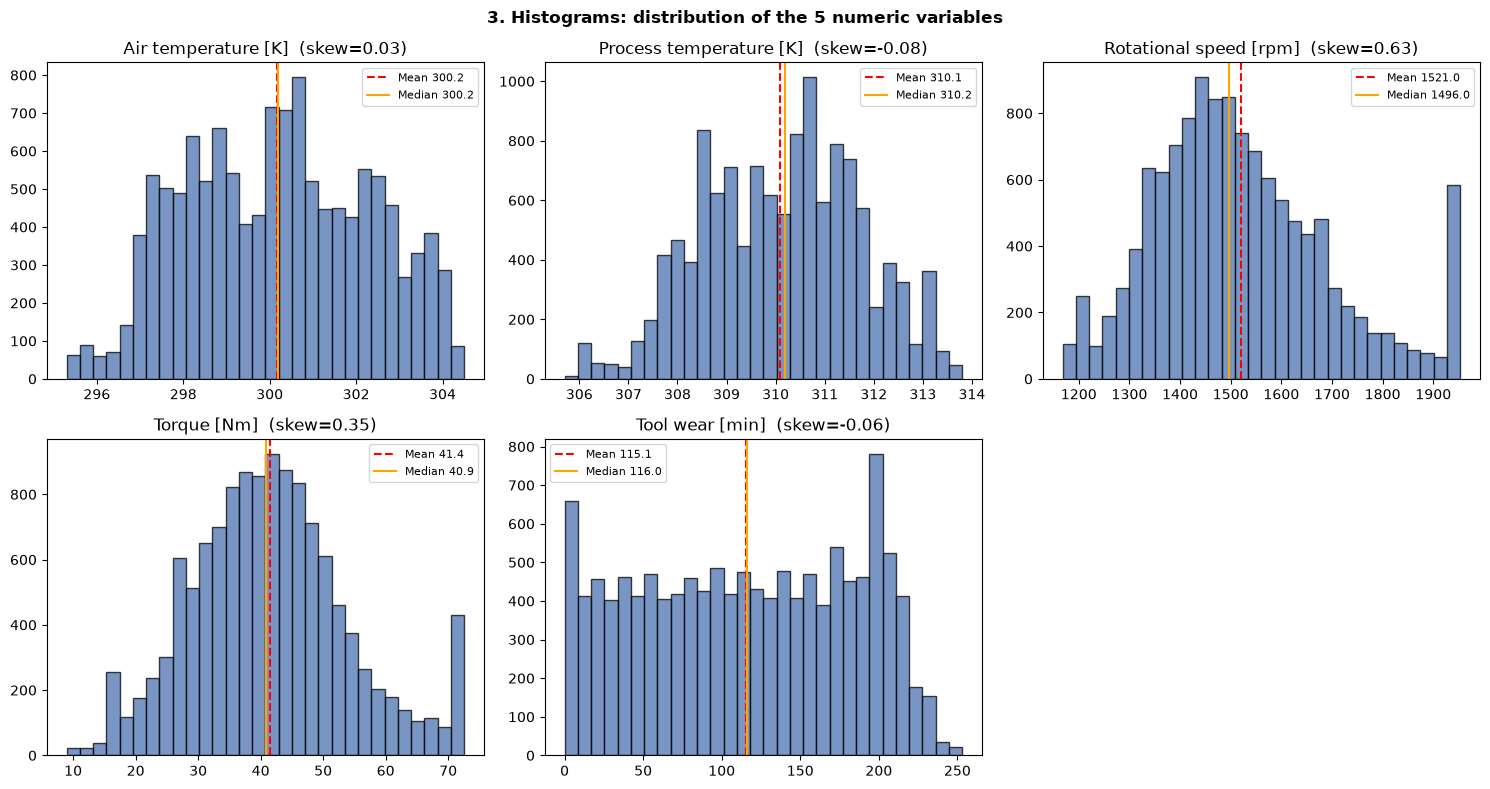

Takeaway: temperatures ~ bell-shaped; rotational speed right-skewed with a spike at 1953 (IQR cap); tool wear ~ uniform.


In [11]:
# 3) HISTOGRAMS — all 5 variables (normality check)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), num_cols):
    ax.hist(df[c], bins=30, color='#4C72B0', edgecolor='black', alpha=0.75)
    ax.axvline(df[c].mean(),   color='red',    linestyle='--', label=f'Mean {df[c].mean():.1f}')
    ax.axvline(df[c].median(), color='orange', linestyle='-',  label=f'Median {df[c].median():.1f}')
    ax.set_title(f'{c}  (skew={df[c].skew():.2f})'); ax.legend(fontsize=8)
axes.ravel()[-1].axis('off')
fig.suptitle('3. Histograms: distribution of the 5 numeric variables', fontweight='bold')
plt.tight_layout(); plt.show()
print('Takeaway: temperatures ~ bell-shaped; rotational speed right-skewed with a spike at 1953 (IQR cap); tool wear ~ uniform.')

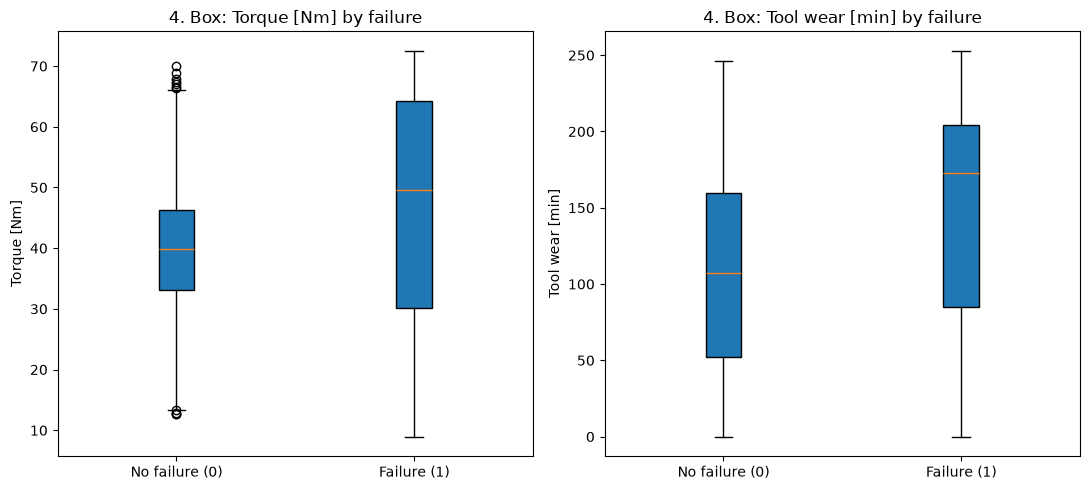

Torque [Nm]: median OK = 39.9 | median Failure = 49.6
Tool wear [min]: median OK = 107.0 | median Failure = 173.0
Takeaway: failed machines run at higher torque and higher wear. No dots beyond the whiskers = the IQR capping from Milestone 2 worked.


In [12]:
# 4) BOX PLOT — Torque and Tool wear by failure status
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, c in zip(axes, ['Torque [Nm]', 'Tool wear [min]']):
    groups = [df.loc[df[target]==0, c], df.loc[df[target]==1, c]]
    ax.boxplot(groups, patch_artist=True)
    ax.set_xticks([1, 2]); ax.set_xticklabels(['No failure (0)', 'Failure (1)'])
    ax.set_title(f'4. Box: {c} by failure'); ax.set_ylabel(c)
plt.tight_layout(); plt.show()

for c in ['Torque [Nm]', 'Tool wear [min]']:
    print(f'{c}: median OK = {df.loc[df[target]==0,c].median():.1f} | median Failure = {df.loc[df[target]==1,c].median():.1f}')
print('Takeaway: failed machines run at higher torque and higher wear. No dots beyond the whiskers = the IQR capping from Milestone 2 worked.')

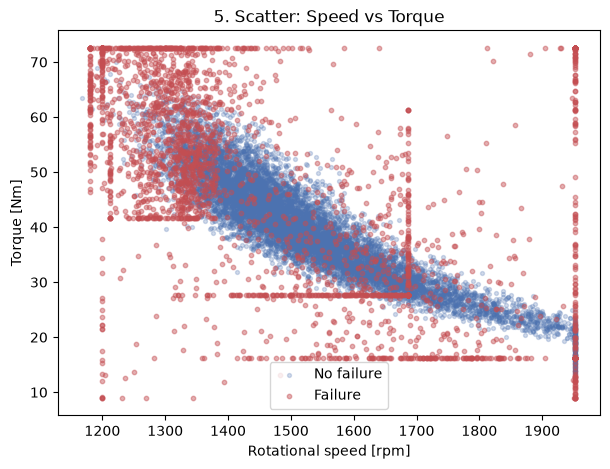

Takeaway: strong inverse relation (r = -0.72) - faster rotation means lower torque (power is roughly constant). Failures cluster at low-speed / high-torque.


In [13]:
# 5) SCATTER — Rotational speed vs Torque (coloured by failure)
plt.figure(figsize=(7, 5))
ok, bad = df[df[target]==0], df[df[target]==1]
plt.scatter(ok['Rotational speed [rpm]'],  ok['Torque [Nm]'],  c='#4C72B0', alpha=0.25, s=8,  label='No failure')
plt.scatter(bad['Rotational speed [rpm]'], bad['Torque [Nm]'], c='#C44E52', alpha=0.45, s=10, label='Failure')
plt.xlabel('Rotational speed [rpm]'); plt.ylabel('Torque [Nm]')
plt.title('5. Scatter: Speed vs Torque'); plt.legend(); plt.show()

r = df['Rotational speed [rpm]'].corr(df['Torque [Nm]'])
print(f'Takeaway: strong inverse relation (r = {r:.2f}) - faster rotation means lower torque (power is roughly constant). Failures cluster at low-speed / high-torque.')

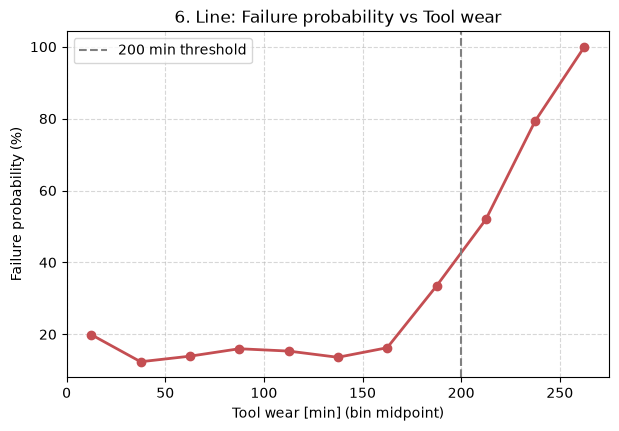

                 Failure %  Rows in bin
Tool wear [min]                        
(-0.001, 25.0]        19.9         1528
(25.0, 50.0]          12.4         1278
(50.0, 75.0]          13.9         1294
(75.0, 100.0]         16.0         1314
(100.0, 125.0]        15.3         1324
(125.0, 150.0]        13.6         1301
(150.0, 175.0]        16.3         1322
(175.0, 200.0]        33.4         1657
(200.0, 225.0]        51.9         1238
(225.0, 250.0]        79.3          237
(250.0, 275.0]       100.0            7
Takeaway: risk stays ~12-20% up to 175 min, then jumps (33% -> 52% -> 79%), supporting preventive replacement before ~200 min.
Caution: the last bin (250-275] has only 7 rows, so its 100% is not reliable - do not quote it.


In [14]:
# 6) LINE — Failure probability across tool-wear bins
# NOTE: include_lowest=True so wear=0 is not dropped, and the bins go to 275 so wear 251-253 is not dropped.
bins = np.arange(0, 276, 25)
wear_bin = pd.cut(df['Tool wear [min]'], bins=bins, include_lowest=True)
wear_trend = df.groupby(wear_bin, observed=False)[target].mean()*100
mid = [iv.mid for iv in wear_trend.index]

plt.figure(figsize=(7, 4.5))
plt.plot(mid, wear_trend.values, marker='o', color='#C44E52', linewidth=2)
plt.axvline(200, color='grey', linestyle='--', label='200 min threshold')
plt.title('6. Line: Failure probability vs Tool wear'); plt.xlabel('Tool wear [min] (bin midpoint)')
plt.ylabel('Failure probability (%)'); plt.grid(True, linestyle='--', alpha=0.5); plt.legend(); plt.show()
counts = df.groupby(wear_bin, observed=False)[target].size()
print(pd.DataFrame({'Failure %': wear_trend.round(1), 'Rows in bin': counts}).to_string())
print('Takeaway: risk stays ~12-20% up to 175 min, then jumps (33% -> 52% -> 79%), supporting preventive replacement before ~200 min.')
print('Caution: the last bin (250-275] has only', int(counts.iloc[-1]), 'rows, so its 100% is not reliable - do not quote it.')

## Step 4 — (Correlation ≠ Causation)

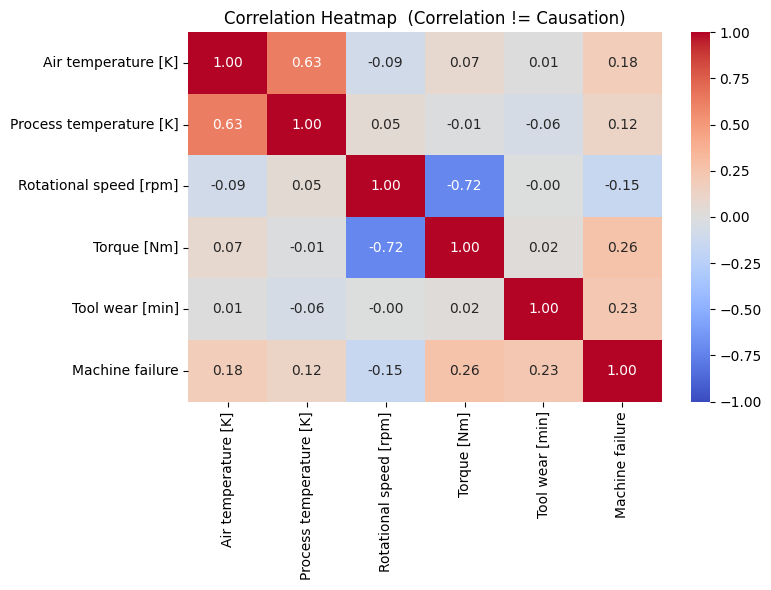

Correlation with Machine failure:
Torque [Nm]                0.26
Tool wear [min]            0.23
Air temperature [K]        0.18
Process temperature [K]    0.12
Rotational speed [rpm]    -0.15

Air temp vs Process temp   : 0.63
Speed vs Torque            : -0.72


In [12]:
corr = df[num_cols + [target]].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Correlation Heatmap  (Correlation != Causation)')
plt.tight_layout(); plt.show()

print('Correlation with Machine failure:')
print(corr[target].drop(target).sort_values(ascending=False).round(2).to_string())
print('\nAir temp vs Process temp   :', round(corr.loc['Air temperature [K]','Process temperature [K]'], 2))
print('Speed vs Torque            :', round(corr.loc['Rotational speed [rpm]','Torque [Nm]'], 2))